In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [ ]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
results_dir = os.path.join(project_dir, '...')

In [3]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## Left and right TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)

# Select the left and right TLE
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# Left TLE (SDx = 0, 3, 5)
idx_left = demo.index[demo["SDx"].isin([0, 3, 5])]
idx_left = idx_img.intersection(idx_left)

demo_left = demo.loc[idx_left]
ctx_left  = ctx_tle.loc[idx_left]
sv_left   = sv_tle.loc[idx_left]

# Right TLE (SDx = 0, 4, 6)
idx_right = demo.index[demo["SDx"].isin([0, 4, 6])]
idx_right = idx_img.intersection(idx_right)

demo_right = demo.loc[idx_right]
ctx_right  = ctx_tle.loc[idx_right]
sv_right   = sv_tle.loc[idx_right]

### Effect of sex and diagnosis-sex interaction across cohorts

In [6]:
## glm comparison 
biomarker_datasets = {
    "tle_left":  {"demo": demo_left,  "ctx": ctx_left,  "sv": sv_left},
    "tle_right": {"demo": demo_right, "ctx": ctx_right, "sv": sv_right},
}

comparison_types = ["sex_group_interaction"]

results = {epi: {b: {} for b in ["ctx", "sv"]} for epi in biomarker_datasets.keys()}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")        

2026-09-02 10:12:01,732 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:12:01,736 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:12:01,738 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:12:01,965 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical va

In [7]:
# Reorganize results

epi_types = ["tle_left", "tle_right"]
biomarkers = ["ctx", "sv"]

comparison_types = ["sex_group_interaction"]

metric_map = {
    "t": "t_values", "q": "q_values",
    "beta": "beta", "ci_lower": "ci_lower", "ci_upper": "ci_upper",
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([
                np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f"{metric_name}_{epi}_{biomarker}"] = values

In [ ]:
## Save

comparison_types = ['sex_group_interaction']
metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
epi_to_save = ['tle_left', 'tle_right']
biomarkers = ['ctx', 'sv']

biomarker_index_map = {"ctx": ctx_tle.columns, "sv": sv_tle.columns}

output_base = os.path.join(results_dir, '...')
os.makedirs(output_base, exist_ok=True)

for epi in epi_to_save:

    # left / right
    _, side = epi.split('_')

    epi_dir = os.path.join(output_base, side)
    os.makedirs(epi_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f"{metric}_{epi}_{biomarker}"

            if key not in result_dicts:
                continue

            values = result_dicts[key]

            df = pd.DataFrame(values.T, index=index_cols, columns=comparison_types)
            df['epi'] = 'TLE'
            df['side'] = side
            df['biomarker'] = biomarker
            df['metric'] = metric

            out_name = f"{metric}_{biomarker}.csv"
            df.to_csv(os.path.join(epi_dir, out_name), index=True)

Sex-diagnosis interaction effects in cortical thickness

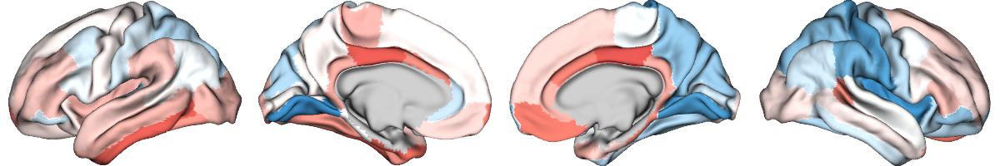

In [21]:
# plot t values in left TLE

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_left_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

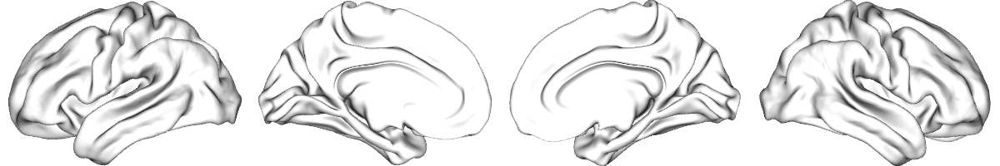

In [19]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

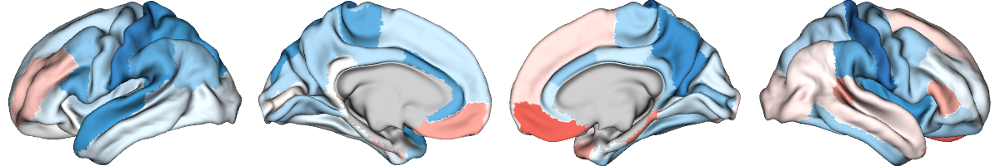

In [24]:
# plot t values in right TLE

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_right_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

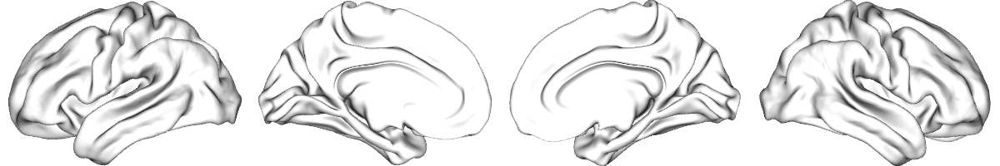

In [25]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

Sex effects in interaction: LTLE

In [33]:
q_ctx_left = pd.Series(result_dicts["q_tle_left_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [35]:
result_dicts["t_tle_left_ctx"].min(), result_dicts["t_tle_left_ctx"].max()

(-1.744736239287169, 1.8788459225085732)

Sex effects in interaction: right TLE

In [37]:
q_ctx_right = pd.Series(result_dicts["q_tle_right_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [38]:
# Right TLE
result_dicts["t_tle_right_ctx"].min(), result_dicts["t_tle_right_ctx"].max()

(-2.4129561911394664, 1.6446302115775715)

Sex * diagnosis interaction effects in subcortical volume

In [43]:
result_dicts["t_tle_left_sv"].shape

(1, 14)

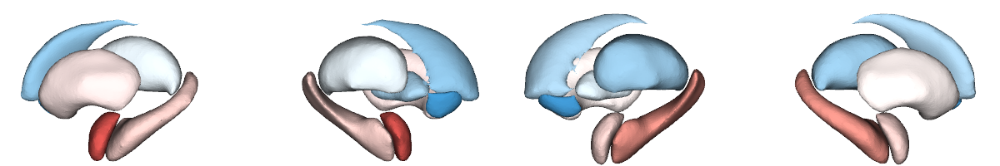

In [44]:
# plot t values in left TLE

plot_subcortical(result_dicts['t_tle_left_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

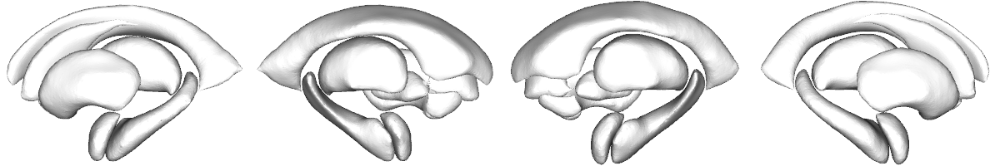

In [45]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

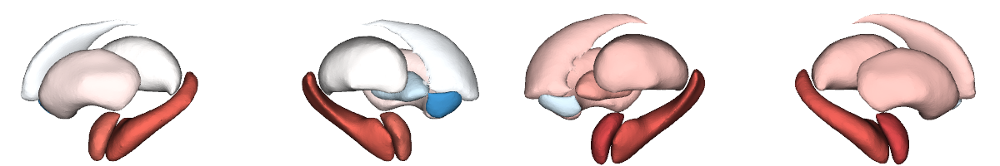

In [46]:
# plot t values in right TLE

plot_subcortical(result_dicts['t_tle_right_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

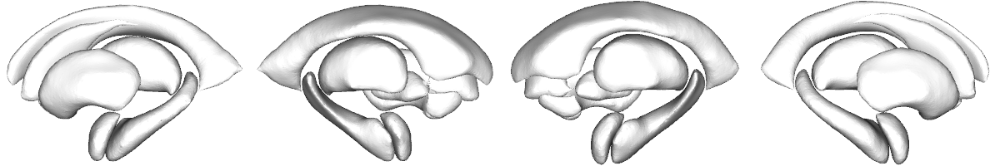

In [47]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [ ]:
# LTLE
q_sv_left = pd.Series(result_dicts["q_tle_left_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [49]:
result_dicts["t_tle_left_sv"][0].min(), result_dicts["t_tle_left_sv"][0].max()

(-1.6314051139139705, 1.8870862129999126)

In [50]:
# Right TLE 
q_sv_right = pd.Series(result_dicts["q_tle_right_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [51]:
result_dicts["t_tle_right_sv"][0].min(), result_dicts["t_tle_right_sv"][0].max()

(-1.6442459379175498, 2.166198786221812)

### Correlation with clinical variables in left and right TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)

# select left and right TLE samples
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# Left TLE (SDx = 3, 5)
idx_left = demo.index[demo["SDx"].isin([3, 5])]
idx_left = idx_img.intersection(idx_left)

demo_left = demo.loc[idx_left]
ctx_left  = ctx_tle.loc[idx_left]
sv_left   = sv_tle.loc[idx_left]

# Right TLE (SDx = 4, 6)
idx_right = demo.index[demo["SDx"].isin([4, 6])]
idx_right = idx_img.intersection(idx_right)

demo_right = demo.loc[idx_right]
ctx_right  = ctx_tle.loc[idx_right]
sv_right   = sv_tle.loc[idx_right]


### clinical correlate, and clinical variables-by sex interaction effects

In [54]:
# GLM comparison
biomarker_datasets = {
    "tle_left": {"demo": demo_left, "ctx": ctx_left, "sv": sv_left},
    "tle_right": {"demo": demo_right, "ctx": ctx_right, "sv": sv_right},
}

comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 10:49:09,668 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:49:09,692 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:49:09,711 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 10:49:09,734 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [55]:
# Reorganize results

epi_types = ["tle_left", "tle_right"]
biomarkers = ["ctx", "sv"]

comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]

metric_map = {
    "t": "t_values", "q": "q_values",
    "beta": "beta", "ci_lower": "ci_lower", "ci_upper": "ci_upper",
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f"{metric_name}_{epi}_{biomarker}"] = values

In [ ]:
## Save

metrics_to_save = ["t", "q", "beta", "ci_lower", "ci_upper"]
epi_to_save = ["tle_left", "tle_right"]
biomarkers = ["ctx", "sv"]
comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]
biomarker_index_map = {"ctx": ctx_tle.columns, "sv": sv_tle.columns}

output_base = os.path.join(results_dir, "...", "clinical_sex_interaction")
os.makedirs(output_base, exist_ok=True)


for row_idx, interaction_name in enumerate(comparison_types):

    interaction_dir = os.path.join(output_base, interaction_name)
    os.makedirs(interaction_dir, exist_ok=True)

    for epi in epi_to_save:

        # tle_left / tle_right
        _, side = epi.split("_")

        side_dir = os.path.join(interaction_dir, side)
        os.makedirs(side_dir, exist_ok=True)

        for biomarker in biomarkers:
            index_cols = biomarker_index_map[biomarker]

            for metric in metrics_to_save:
                key = f"{metric}_{epi}_{biomarker}"

                if key not in result_dicts:
                    continue

                values_all = result_dicts[key]
                values = values_all[row_idx, :]

                df = pd.DataFrame(values, index=index_cols, columns=[f"{metric}_value"])
                df["analysis"] = "sex interaction with clinical variable"
                df["interaction"] = interaction_name
                df["predictor"] = ("disease duration" if interaction_name == "duration_sex_interaction" else "age of onset")
                df["diagnosis"] = "TLE"
                df["side"] = side
                df["metric"] = metric
                df["biomarker"] = biomarker

                out_name = f"{metric}_{biomarker}.csv"
                df.to_csv(os.path.join(side_dir, out_name), index=True)

#### Sex * disease duration interaction effects in cortical thickness

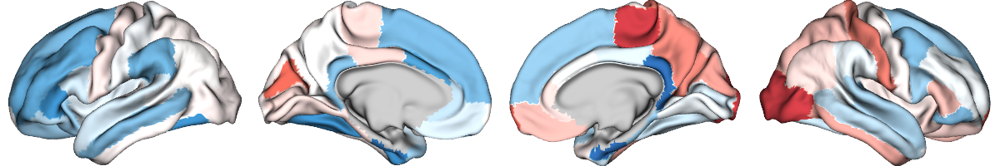

In [60]:
# plot t values in left TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_left_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

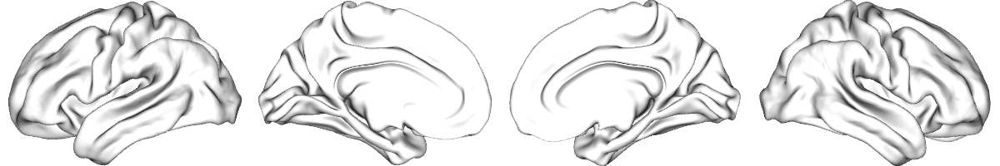

In [61]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

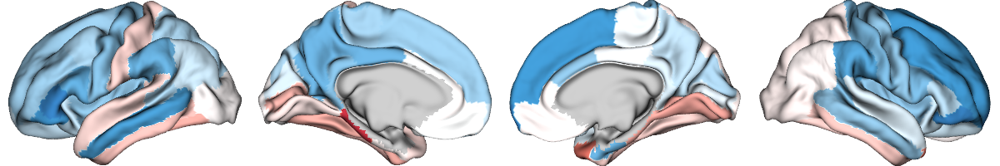

In [62]:
# plot t values in right TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_right_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

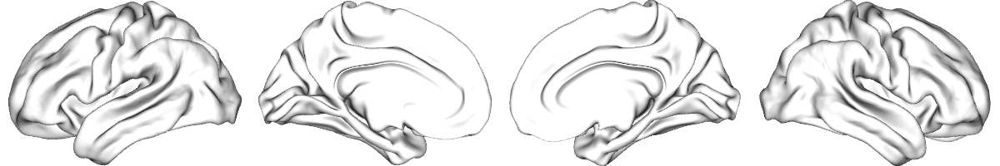

In [63]:
# plot p -sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [64]:
# Left TLE

q_ctx_left = pd.Series(result_dicts["q_tle_left_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [65]:
# LTLE
result_dicts["t_tle_left_ctx"][0].min(), result_dicts["t_tle_left_ctx"][0].max()

(-2.6191906789444954, 2.3617501915410575)

In [66]:
# Right TLE

q_ctx_right = pd.Series(result_dicts["q_tle_right_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [67]:
# RTLE
result_dicts["t_tle_right_ctx"][0].min(), result_dicts["t_tle_right_ctx"][0].max()

(-2.129341443362852, 2.5547707142139107)

#### Sex * age of onset interaction effects cortical thickness

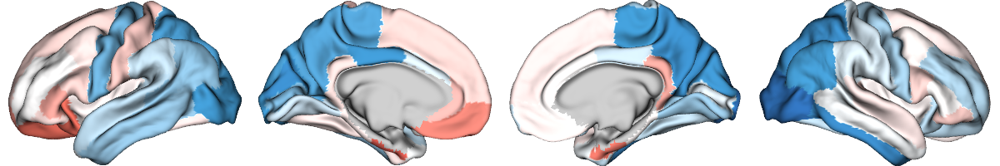

In [68]:
# plot t values in left TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_left_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

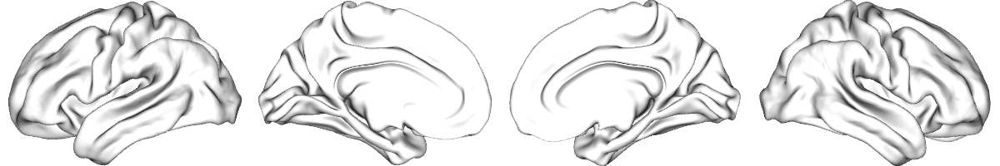

In [69]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_left_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

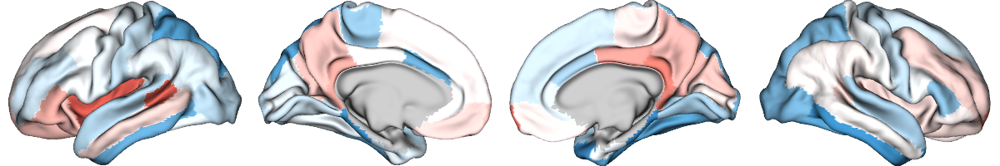

In [71]:
# plot t values in right TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_right_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

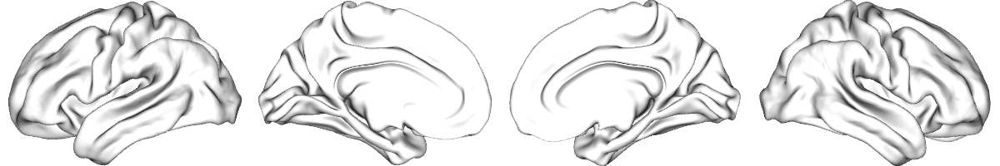

In [72]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_right_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [73]:
# Left TLE 

q_ctx_left = pd.Series(result_dicts["q_tle_left_ctx"][1], index=ctx_tle.columns, name="qFDR")

sig_ctx_left = q_ctx_left[q_ctx_left < 0.05].index
sig_ctx_left

Index([], dtype='object')

In [74]:
# LTLE
result_dicts["t_tle_left_ctx"][1].min(), result_dicts["t_tle_left_ctx"][1].max()

(-2.545576663635636, 1.6504102937333296)

In [75]:
# Right TLE 

q_ctx_right = pd.Series(result_dicts["q_tle_right_ctx"][1], index=ctx_tle.columns, name="qFDR")

sig_ctx_right = q_ctx_right[q_ctx_right < 0.05].index
sig_ctx_right

Index([], dtype='object')

In [77]:
# RTLE
result_dicts["t_tle_right_ctx"][1].min(), result_dicts["t_tle_right_ctx"][1].max()

(-1.9316657749403687, 1.7410170175652866)

#### Sex * disease duration interaction effects in subcortical volume

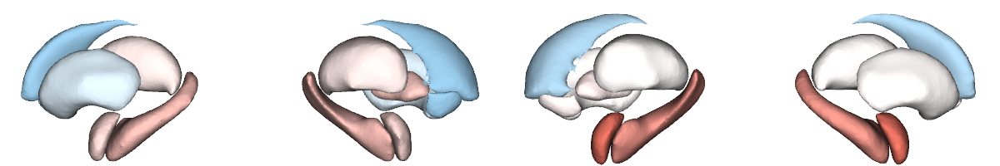

In [78]:
# plot t values in left TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_left_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

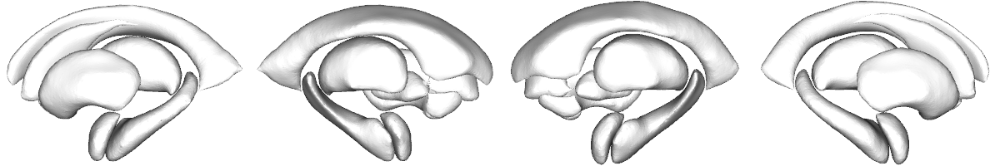

In [79]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

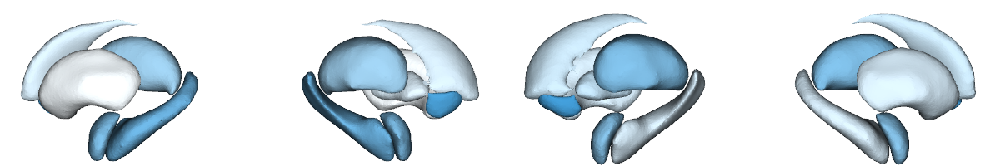

In [81]:
# plot cohen values in right TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_right_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

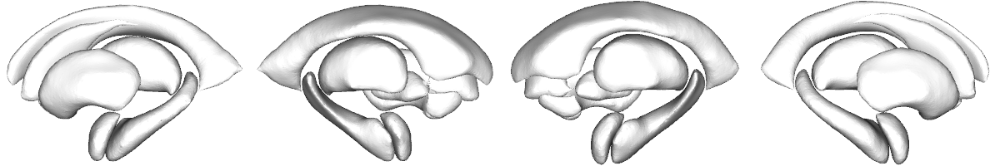

In [82]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_right_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [83]:
# Left TLE 

q_sv_left = pd.Series(result_dicts["q_tle_left_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [85]:
result_dicts["t_tle_left_sv"][0].min(), result_dicts["t_tle_left_sv"][0].max()

(-0.8391506641050808, 1.3964166977729742)

In [86]:
# Right TLE 

q_sv_right = pd.Series(result_dicts["q_tle_right_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [87]:
result_dicts["t_tle_right_sv"][0].min(), result_dicts["t_tle_right_sv"][0].max()

(-1.557009075100828, -0.1075823711002438)

#### Sex* age of onset interaction effects in subcortical volume

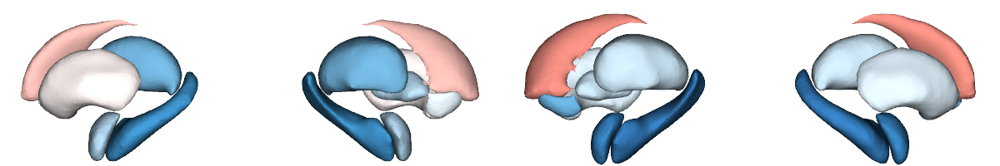

In [88]:
# plot t values in left TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_left_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

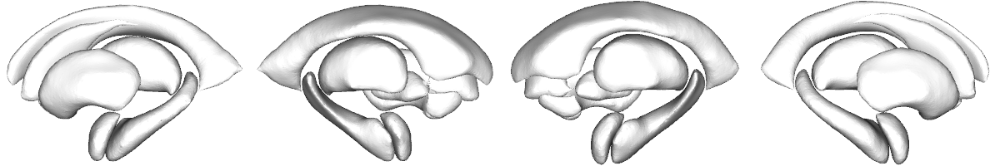

In [89]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_left_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

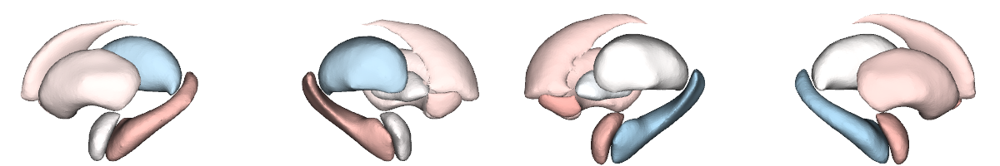

In [90]:
# plot t values in right TLE

plot_subcortical(result_dicts['t_tle_right_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

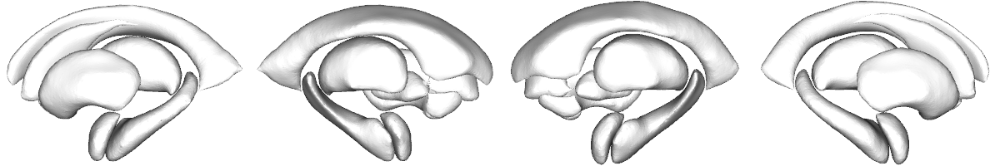

In [91]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_right_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [93]:
# Left TLE

q_sv_left = pd.Series(result_dicts["q_tle_left_sv"][1], index=sv_tle.columns, name="pFDR")
q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [94]:
result_dicts["t_tle_left_sv"][1].min(), result_dicts["t_tle_left_sv"][1].max()

(-2.152479440733106, 1.1328128822497434)

In [95]:
# Right TLE 

q_sv_right = pd.Series(result_dicts["q_tle_right_sv"][1], index=sv_tle.columns, name="pFDR")
q_sv_right[q_sv_right < 0.05].index

Index([], dtype='object')

In [96]:
result_dicts["t_tle_right_sv"][1].min(), result_dicts["t_tle_right_sv"][1].max()

(-0.6951499875815617, 0.7961140194329261)

## MTS and Non-lesional TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)

# Sort out the MTS and Non-lesional samples
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# MTS TLE (SDx = 3, 4)
idx_mts = demo.index[demo["SDx"].isin([0, 3, 4])]
idx_mts = idx_img.intersection(idx_mts)

demo_mts = demo.loc[idx_mts]
ctx_mts  = ctx_tle.loc[idx_mts]
sv_mts   = sv_tle.loc[idx_mts]

# Non-lesional TLE (SDx = 5, 6)
idx_nonlesional = demo.index[demo["SDx"].isin([0, 5, 6])]
idx_nonlesional = idx_img.intersection(idx_nonlesional)

demo_nonlesional = demo.loc[idx_nonlesional]
ctx_nonlesional  = ctx_tle.loc[idx_nonlesional]
sv_nonlesional   = sv_tle.loc[idx_nonlesional]

### Effect of sex and diagnosis-sex interaction across cohorts

In [99]:
## glm comparison 
biomarker_datasets = {
    "tle_mts": {"demo": demo_mts, "ctx": ctx_mts, "sv": sv_mts},
    "tle_nonlesional": {"demo": demo_nonlesional, "ctx": ctx_nonlesional, "sv": sv_nonlesional},
}

comparison_types = ["sex_group_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-09-02 11:30:25,055 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:30:25,059 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:30:25,062 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:30:25,261 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical va

In [100]:
# Reorganize results

epi_types = ["tle_mts", "tle_nonlesional"]

biomarkers = ["ctx", "sv"]

comparison_types = ["sex_group_interaction"]

metric_map = {
    "t": "t_values", "q": "q_values",
    "beta": "beta", "ci_lower": "ci_lower", "ci_upper": "ci_upper",
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([
                np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f"{metric_name}_{epi}_{biomarker}"] = values

In [ ]:
## Save 

comparison_types = ["sex_group_interaction"]
metrics_to_save = ["t", "q", "beta", "ci_lower", "ci_upper"]
epi_to_save = ["tle_mts", "tle_nonlesional"]
biomarkers = ["ctx", "sv"]
biomarker_index_map = {"ctx": ctx_tle.columns, "sv": sv_tle.columns}

output_base = os.path.join(results_dir, "...")
os.makedirs(output_base, exist_ok=True)

for epi in epi_to_save:

    # tle_mts / tle_nonlesional
    _, lesion = epi.split("_")

    lesion_dir = os.path.join(output_base, lesion)
    os.makedirs(lesion_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f"{metric}_{epi}_{biomarker}"

            if key not in result_dicts:
                continue

            values = result_dicts[key]

            df = pd.DataFrame(values.T, index=index_cols, columns=comparison_types)
            df["diagnosis"] = "TLE"
            df["lesion_status"] = lesion
            df["biomarker"] = biomarker
            df["metric"] = metric

            out_name = f"{metric}_{biomarker}.csv"
            df.to_csv(os.path.join(lesion_dir, out_name), index=True)

#### Sex diagnosis interaction effects in cortical thickness

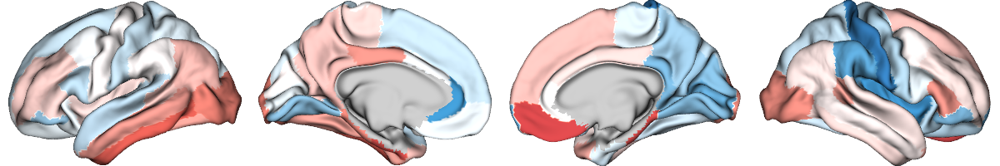

In [103]:
# plot t values in MTS TLE
# label_text = ['sex_group_interaction']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_mts_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

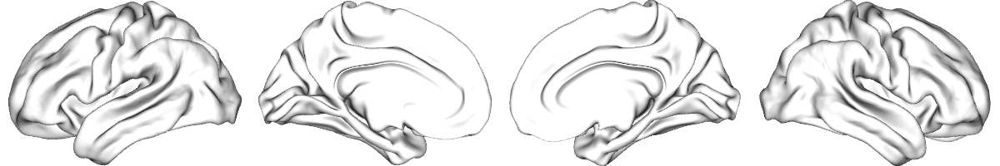

In [104]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

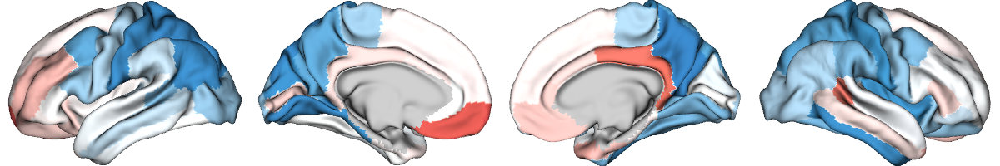

In [106]:
# plot t values in nonlesional TLE

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_nonlesional_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

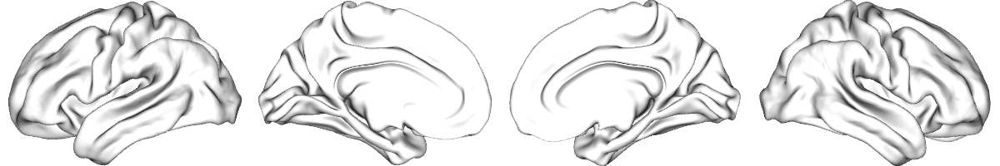

In [107]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [109]:
q_ctx_mts = pd.Series(result_dicts["q_tle_mts_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_mts = q_ctx_mts[q_ctx_mts < 0.05].index
sig_ctx_mts

Index([], dtype='object')

In [111]:
result_dicts["t_tle_mts_ctx"].min(), result_dicts["t_tle_mts_ctx"].max()

(-2.0627500847715385, 2.16888227204468)

Sex effects in interaction: TLE-nonlesional

In [112]:
q_ctx_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_nonlesional = q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index
sig_ctx_nonlesional

Index([], dtype='object')

In [113]:
result_dicts["t_tle_nonlesional_ctx"].min(), result_dicts["t_tle_nonlesional_ctx"].max()

(-2.0425819844266337, 2.0425921585642035)

Sex diagnosis interaction effects in subcortical volume

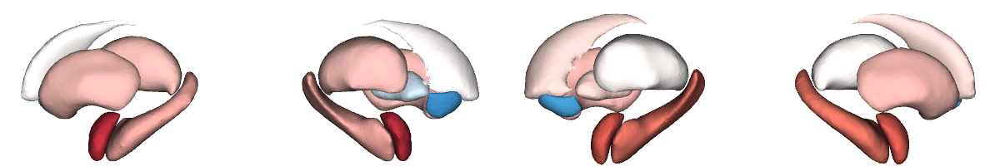

In [116]:
# plot t values in mts TLE
# label_text = ['sex_group_interaction']

plot_subcortical(result_dicts['t_tle_mts_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

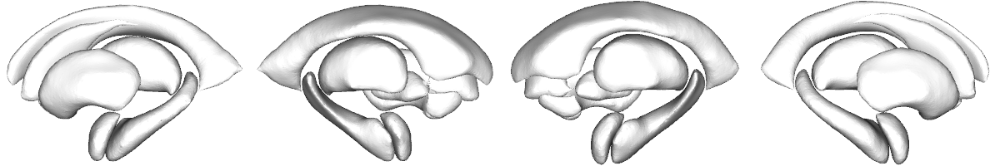

In [118]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

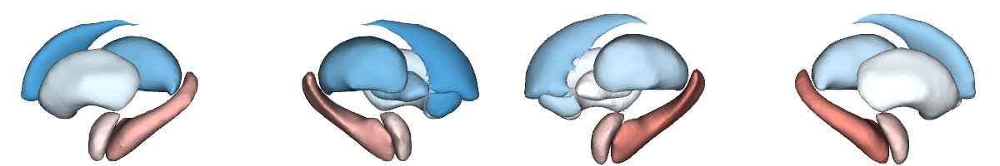

In [119]:
# plot cohen values in nonlesional TLE
# label_text = ['sex_group_interaction']

plot_subcortical(result_dicts['t_tle_nonlesional_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

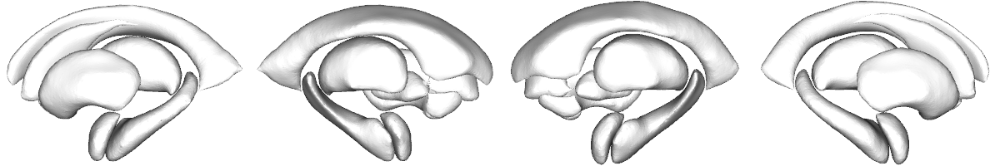

In [120]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [123]:
# MTS TLE
q_sv_mts = pd.Series(result_dicts["q_tle_mts_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_mts[q_sv_mts < 0.05].index

Index([], dtype='object')

In [122]:
result_dicts["t_tle_mts_sv"].min(), result_dicts["t_tle_mts_sv"].max()

(-1.7998413128419253, 2.6266658801515343)

In [125]:
# nonlesional TLE 
q_sv_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_nonlesional[q_sv_nonlesional < 0.05].index

Index([], dtype='object')

In [126]:
result_dicts["t_tle_nonlesional_sv"].min(), result_dicts["t_tle_nonlesional_sv"].max()

(-1.4200878114107494, 1.142313726955627)

### Correlation with clinical variables in MTS and Non-lesional TLE

In [ ]:
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)

# Select the mts and non-lesional TLE participants
idx_img = (ctx_tle.index.intersection(sv_tle.index))

# MTS TLE
idx_mts = demo.index[demo["SDx"].isin([3, 4])]
idx_mts = idx_img.intersection(idx_mts)

demo_mts = demo.loc[idx_mts]
ctx_mts  = ctx_tle.loc[idx_mts]
sv_mts   = sv_tle.loc[idx_mts]

# Non-lesional TLE
idx_nonlesional = demo.index[demo["SDx"].isin([5, 6])]
idx_nonlesional = idx_img.intersection(idx_nonlesional)

demo_nonlesional = demo.loc[idx_nonlesional]
ctx_nonlesional  = ctx_tle.loc[idx_nonlesional]
sv_nonlesional   = sv_tle.loc[idx_nonlesional]

In [129]:
# glm comparison
biomarker_datasets = {
    "tle_mts": {"demo": demo_mts, "ctx": ctx_mts, "sv": sv_mts},
    "tle_nonlesional": {"demo": demo_nonlesional, "ctx": ctx_nonlesional, "sv": sv_nonlesional},
}

comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]

results = {
    epi: {b: {} for b in ["ctx", "sv"]}
    for epi in biomarker_datasets.keys()
}

for epi, pack in biomarker_datasets.items():
    demo_sub = pack["demo"]

    for biomarker in ["ctx", "sv"]:
        biomarker_df = pack[biomarker]

        glm = general_linear_model(demo_sub, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 11:49:47,244 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:49:47,275 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:49:47,294 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 11:49:47,317 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [130]:
# Reorganize results

epi_types = ["tle_mts", "tle_nonlesional"]

biomarkers = ["ctx", "sv"]

comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]

metric_map = {
    "t": "t_values", "q": "q_values",
    "beta": "beta", "ci_lower": "ci_lower", "ci_upper": "ci_upper",
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f"{metric_name}_{epi}_{biomarker}"] = values

In [ ]:
## Save 

metrics_to_save = ["t", "q", "beta", "ci_lower", "ci_upper"]
epi_to_save = ["tle_mts", "tle_nonlesional"]
biomarkers = ["ctx", "sv"]
comparison_types = ["duration_sex_interaction", "ao_sex_interaction"]
biomarker_index_map = {"ctx": ctx_tle.columns, "sv": sv_tle.columns}

output_base = os.path.join(results_dir, "...", "clinical_sex_interaction")
os.makedirs(output_base, exist_ok=True)

for row_idx, interaction_name in enumerate(comparison_types):

    interaction_dir = os.path.join(output_base, interaction_name)
    os.makedirs(interaction_dir, exist_ok=True)

    for epi in epi_to_save:

        # tle_mts / tle_nonlesional
        _, lesion = epi.split("_")
        lesion_dir = os.path.join(interaction_dir, lesion)
        os.makedirs(lesion_dir, exist_ok=True)

        for biomarker in biomarkers:
            index_cols = biomarker_index_map[biomarker]

            for metric in metrics_to_save:
                key = f"{metric}_{epi}_{biomarker}"

                if key not in result_dicts:
                    continue

                values_all = result_dicts[key]
                values = values_all[row_idx, :]

                df = pd.DataFrame(values, index=index_cols, columns=[f"{metric}_value"])
                df["analysis"] = "sex interaction with clinical variable"
                df["interaction"] = interaction_name
                df["predictor"] = ("disease duration" if interaction_name == "duration_sex_interaction" else "age of onset")
                df["diagnosis"] = "TLE"
                df["lesion_status"] = lesion
                df["metric"] = metric
                df["biomarker"] = biomarker

                out_name = f"{metric}_{biomarker}.csv"
                df.to_csv(os.path.join(lesion_dir, out_name), index=True)

Sex * disease duration interaction effects in cortical thickness

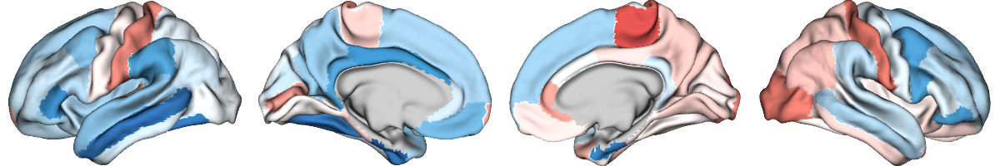

In [133]:
# plot t values in MTS TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_mts_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

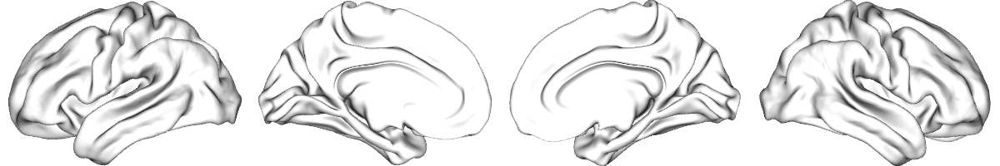

In [134]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

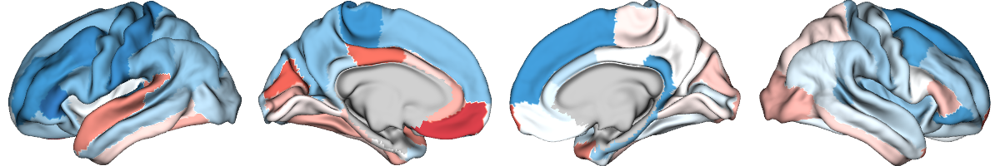

In [135]:
# plot t values in nonlesional TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_nonlesional_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

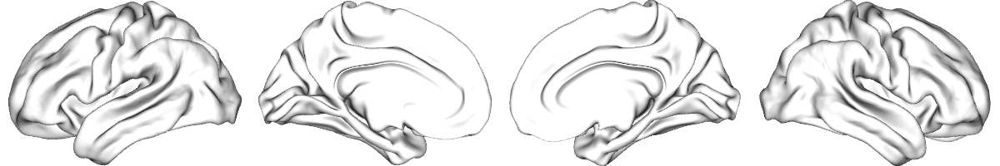

In [136]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [137]:
q_ctx_mts = pd.Series(result_dicts["q_tle_mts_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_mts = q_ctx_mts[q_ctx_mts < 0.05].index
sig_ctx_mts

Index([], dtype='object')

In [138]:
# MTS
result_dicts["t_tle_mts_ctx"][0].min(), result_dicts["t_tle_mts_ctx"][0].max()

(-3.3477992169126876, 1.957352697549177)

In [139]:
# Non-lesional 
q_ctx_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_ctx"][0], index=ctx_tle.columns, name="qFDR")

sig_ctx_nonlesional = q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index
sig_ctx_nonlesional

Index([], dtype='object')

In [140]:
# Non-lesional
result_dicts["t_tle_nonlesional_ctx"][0].min(), result_dicts["t_tle_nonlesional_ctx"][0].max()

(-2.2825246832226775, 2.380772208348986)

Sex * age of onset interaction effects in cortical thickness

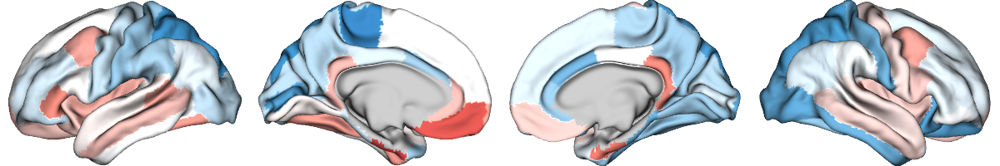

In [142]:
# plot t values in MTS TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_mts_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

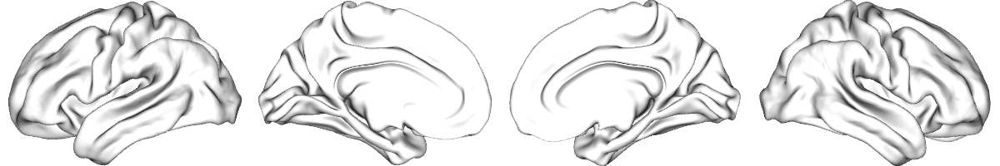

In [143]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_mts_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

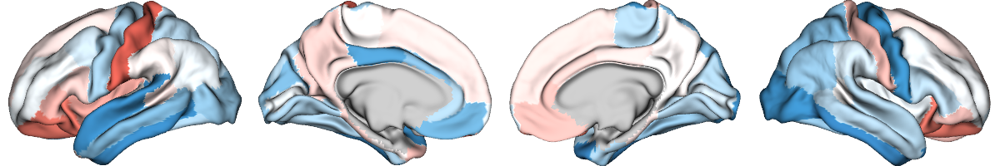

In [145]:
# plot t values in nonlesional TLE
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_nonlesional_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

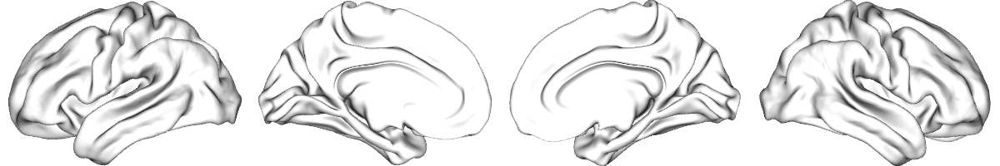

In [146]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_nonlesional_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [147]:
# MTS 
q_ctx_mts = pd.Series(result_dicts["q_tle_mts_ctx"][1], index=ctx_tle.columns, name="pFDR")
q_ctx_mts[q_ctx_mts < 0.05].index

Index([], dtype='object')

In [148]:
result_dicts["t_tle_mts_ctx"][1].min(), result_dicts["t_tle_mts_ctx"][1].max()

(-1.8782896283611967, 2.148502299638079)

In [149]:
# Non-lesional
q_ctx_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_ctx"][1], index=ctx_tle.columns, name="pFDR")
q_ctx_nonlesional[q_ctx_nonlesional < 0.05].index

Index([], dtype='object')

In [150]:
result_dicts["t_tle_nonlesional_ctx"][1].min(), result_dicts["t_tle_nonlesional_ctx"][1].max()

(-1.9210552850466638, 1.5723382803994272)

#### Sex * disease duration interaction effects in subcortical volume

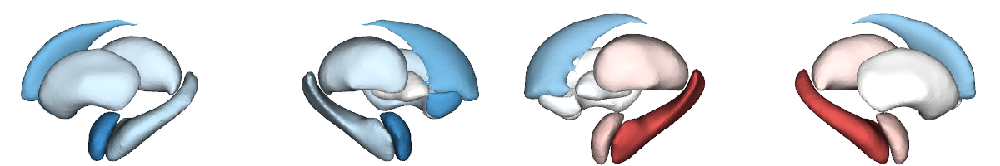

In [152]:
# plot t values in mts TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_mts_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

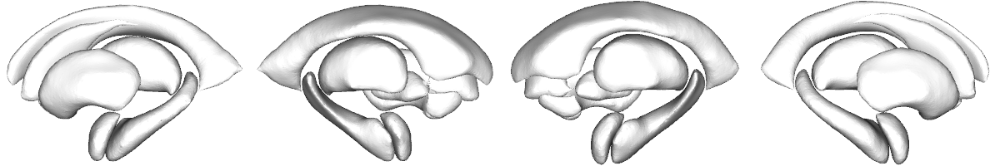

In [153]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

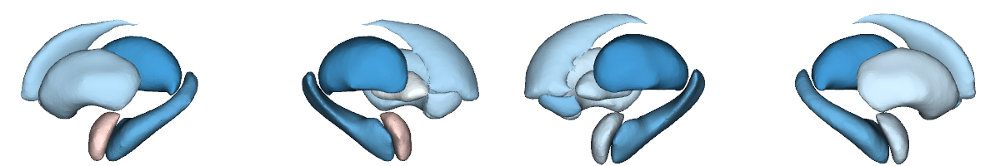

In [154]:
# plot t values in nonlesional TLE

plot_subcortical(result_dicts['t_tle_nonlesional_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

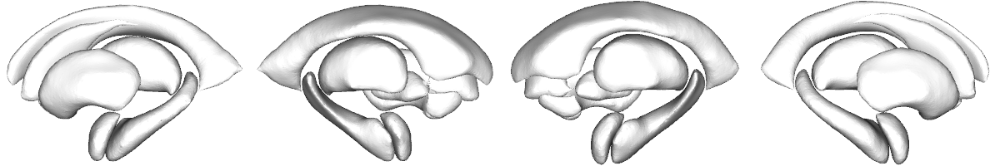

In [155]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [156]:
# duration
q_sv_mts = pd.Series(result_dicts["q_tle_mts_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_mts[q_sv_mts < 0.05].index

Index([], dtype='object')

In [158]:
result_dicts["t_tle_mts_sv"][0].min(), result_dicts["t_tle_mts_sv"][0].max()

(-1.8549826301442773, 1.9664784125924375)

In [157]:
# nonlesional TLE 
q_sv_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_sv"][0], index=sv_tle.columns, name="pFDR")
q_sv_nonlesional[q_sv_nonlesional < 0.05].index

Index([], dtype='object')

In [159]:
result_dicts["t_tle_nonlesional_sv"][0].min(), result_dicts["t_tle_nonlesional_sv"][0].max()

(-1.5958841135045083, 0.437736607727413)

#### Sex* age of onset interaction effects in subcortical volume

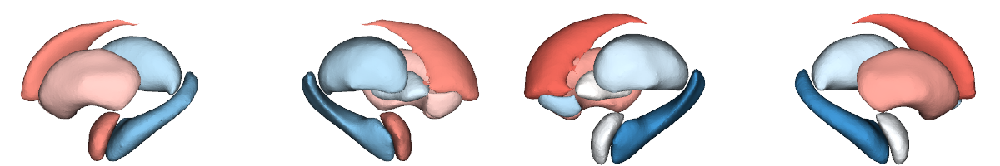

In [160]:
# plot t values in mts TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_mts_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

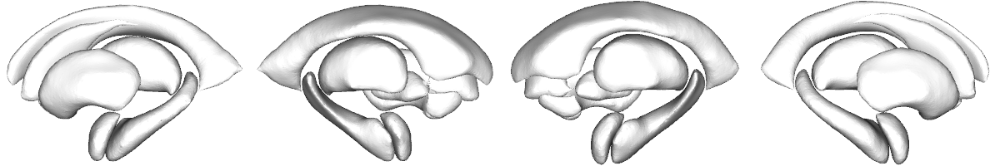

In [161]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_mts_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

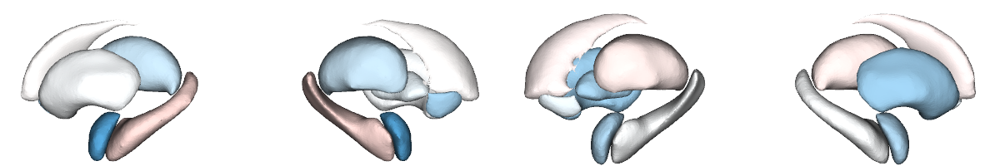

In [162]:
# plot t values in nonlesional TLE
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_nonlesional_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-3, 3))

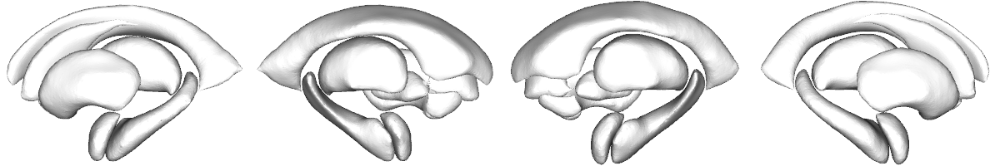

In [163]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_nonlesional_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [164]:
# MTS 
q_sv_mts = pd.Series(result_dicts["q_tle_mts_sv"][1], index=sv_tle.columns, name="pFDR")
q_sv_mts[q_sv_mts < 0.05].index

Index([], dtype='object')

In [167]:
result_dicts["t_tle_mts_sv"][1].min(), result_dicts["t_tle_mts_sv"][1].max()

(-1.754593550843417, 1.6302757914126857)

In [165]:
# Non-lesional 
q_sv_nonlesional = pd.Series(result_dicts["q_tle_nonlesional_sv"][1], index=sv_tle.columns, name="pFDR")
q_sv_nonlesional[q_sv_nonlesional < 0.05].index

Index([], dtype='object')

In [169]:
result_dicts["t_tle_nonlesional_sv"][1].min(), result_dicts["t_tle_nonlesional_sv"][1].max()

(-1.3553530764463317, 0.421723788371989)